In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load data with parsed date column
df = pd.read_csv('applicants_cleaned.csv', parse_dates=['Application Date'])

# Sanity check
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76 entries, 0 to 75
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Applicant Name    76 non-null     object        
 1   Email             76 non-null     object        
 2   Phone             76 non-null     int64         
 3   Domain Applied    76 non-null     object        
 4   University        76 non-null     object        
 5   Application Date  76 non-null     datetime64[ns]
 6   Status            76 non-null     object        
dtypes: datetime64[ns](1), int64(1), object(5)
memory usage: 4.3+ KB


,Applicant Name,Email,Phone,Domain Applied,University,Application Date,Status
0,Allison Hill,donaldgarcia@example.net,3018196001,Cloud Computing,NUST,2026-09-02,Under Review
1,Alyssa Gonzalez,lrobinson@example.com,3020265423,Cloud Computing,LUMS,2026-10-16,Selected
2,Brandon Davis,cassandra07@example.net,3011618495,Web Development,FAST,2026-09-23,Rejected
3,Amber Perez,tracie31@example.com,3024752553,Web Development,GIKI,2026-09-29,Rejected
4,Melinda Jones,amandasanchez@example.com,3016483503,Cybersecurity,UET,2026-10-08,Under Review


## Step 3: Which Domain Received the Most Applications?
Answering with category counts first using `value_counts()`, then visualizing the distribution with a bar chart.

Domain Applied
Web Development    23
Data Science       16
Cloud Computing    15
Cybersecurity      11
AI/ML              11
Name: count, dtype: int64


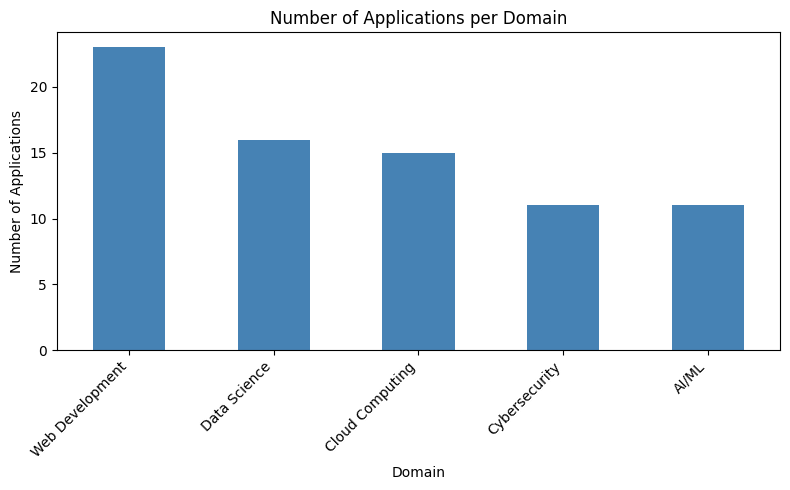

In [18]:
# 1. Count applications per domain
domain_counts = df['Domain Applied'].value_counts()
print(domain_counts)

# 2. Bar chart visualization
plt.figure(figsize=(8, 5))
domain_counts.plot(kind='bar', color='steelblue')
plt.title('Number of Applications per Domain')
plt.xlabel('Domain')
plt.ylabel('Number of Applications')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

> **Takeaway:** Look at the numbers printed above your chart and fill in the blanks: "[Highest Domain] received the highest number of applications ([X]), while [Lowest Domain] received the lowest ([Y])."

## Step 4: How Did Applications Trend Over Time?
Grouping applications by month to track submission velocity across the timeline.

Application Month
2026-02     2
2026-03     1
2026-04     6
2026-05     1
2026-06     3
2026-07     2
2026-08    15
2026-09    33
2026-10    13
Freq: M, dtype: int64


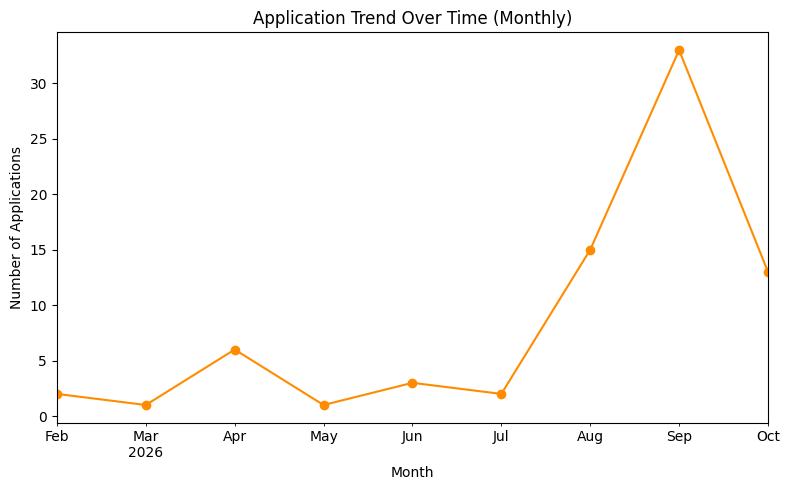

In [19]:
# 1. Group by month
df['Application Month'] = df['Application Date'].dt.to_period('M')
monthly_trend = df.groupby('Application Month').size()
print(monthly_trend)

# 2. Line chart visualization
plt.figure(figsize=(8, 5))
monthly_trend.plot(kind='line', marker='o', color='darkorange')
plt.title('Application Trend Over Time (Monthly)')
plt.xlabel('Month')
plt.ylabel('Number of Applications')
plt.tight_layout()
plt.show()

> **Takeaway:** Applications peaked sharply in September 2026 with 33 submissions (up from 15 in August), before declining to 13 in October as the recruitment window came to a close.

## Step 5: What's the Acceptance Rate Overall and Per Domain?
Examining application outcomes across domains using aggregation, pivot tables, percentage breakdowns, and visualizations (pie chart for overall distribution and grouped bar chart per domain).

In [20]:
# 1. Overall status counts
status_counts = df['Status'].value_counts()
print("Overall Status Counts:")
print(status_counts)

# 2. Pivot table per domain
status_by_domain = pd.pivot_table(
    df,
    index='Domain Applied',
    columns='Status',
    values='Applicant Name',
    aggfunc='count',
    fill_value=0
)
print("\nStatus by Domain (Counts):")
print(status_by_domain)

# 3. Acceptance rate (percentage breakdown per domain)
status_by_domain_pct = status_by_domain.div(status_by_domain.sum(axis=1), axis=0) * 100
print("\nStatus by Domain (%):")
print(status_by_domain_pct.round(1))

Overall Status Counts:
Status
Selected        29
Rejected        28
Under Review    19
Name: count, dtype: int64

Status by Domain (Counts):
Status           Rejected  Selected  Under Review
Domain Applied                                   
AI/ML                   3         3             5
Cloud Computing         3         6             6
Cybersecurity           4         6             1
Data Science            6         7             3
Web Development        12         7             4

Status by Domain (%):
Status           Rejected  Selected  Under Review
Domain Applied                                   
AI/ML                27.3      27.3          45.5
Cloud Computing      20.0      40.0          40.0
Cybersecurity        36.4      54.5           9.1
Data Science         37.5      43.8          18.8
Web Development      52.2      30.4          17.4


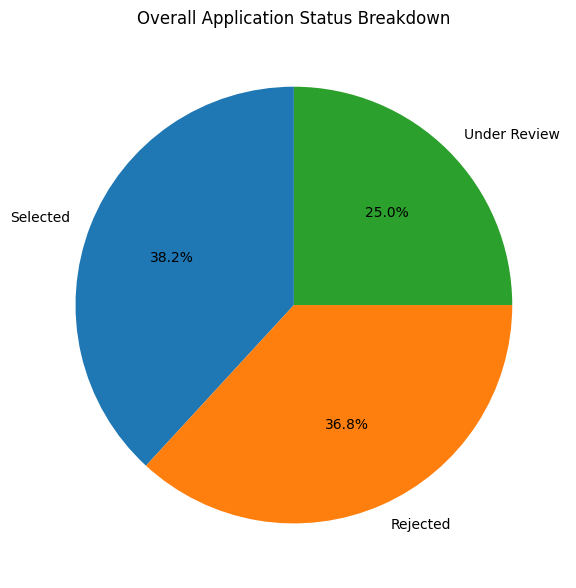

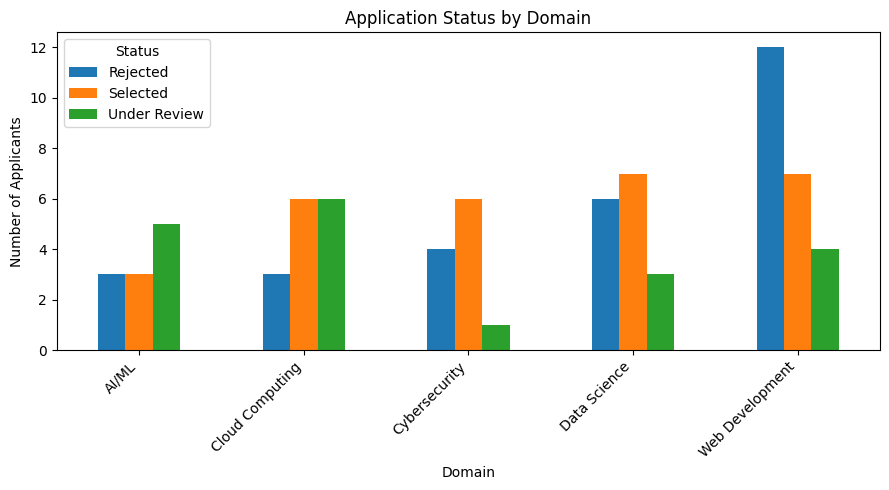

In [21]:
# Chart 1: Overall status pie chart
plt.figure(figsize=(6, 6))
status_counts.plot(kind='pie', autopct='%1.1f%%', startangle=90)
plt.title('Overall Application Status Breakdown')
plt.ylabel('')  # Removes the default y-label
plt.tight_layout()
plt.show()

# Chart 2: Per-domain grouped bar chart
status_by_domain.plot(kind='bar', figsize=(9, 5))
plt.title('Application Status by Domain')
plt.xlabel('Domain')
plt.ylabel('Number of Applicants')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Status')
plt.tight_layout()
plt.show()

> **Takeaway:** The pie chart illustrates the overall distribution of accepted, rejected, and under-review candidates, while the grouped bar chart highlights variation in selection rates across individual domains[cite: 4].

## Step 6: Which Universities Sent the Most Applicants?
Identifying the top 10 feeder institutions using `value_counts().head(10)` and displaying them with a horizontal bar chart (`barh`) for readable campus names[cite: 4, 5].

Top 10 Universities:
University
UET              15
Not Specified    13
FAST             11
LUMS             10
NUST             10
GIKI              9
COMSATS           8
Name: count, dtype: int64


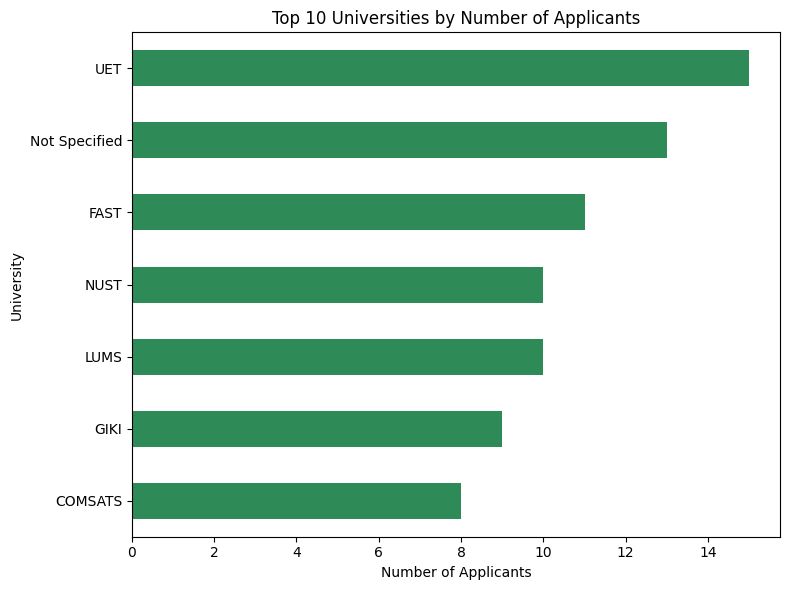

In [22]:
# 1. Top 10 universities
top_universities = df['University'].value_counts().head(10)
print("Top 10 Universities:")
print(top_universities)

# 2. Horizontal bar chart
plt.figure(figsize=(8, 6))
top_universities.sort_values().plot(kind='barh', color='seagreen')
plt.title('Top 10 Universities by Number of Applicants')
plt.xlabel('Number of Applicants')
plt.ylabel('University')
plt.tight_layout()
plt.show()

Applications by Day of the Week:
Day of Week
Monday        9
Tuesday      15
Wednesday    12
Thursday     18
Friday       12
Saturday      5
Sunday        5
Name: count, dtype: int64


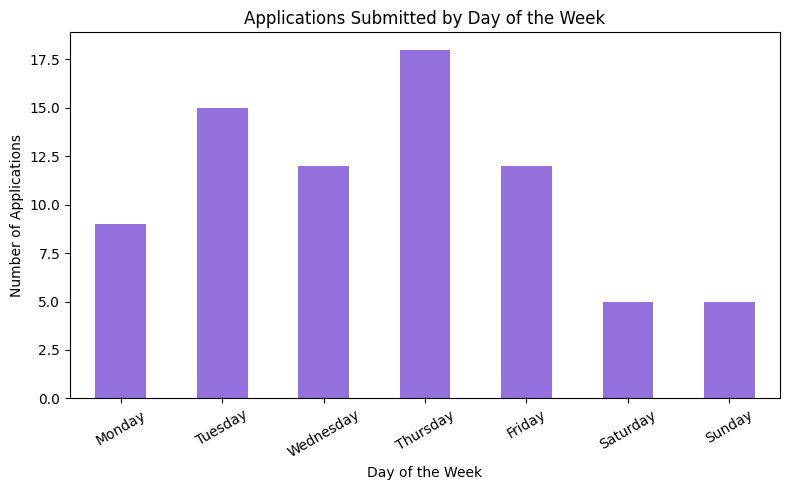

In [23]:
# 1. Extract day name and reorder from Monday to Sunday
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
df['Day of Week'] = df['Application Date'].dt.day_name()
day_counts = df['Day of Week'].value_counts().reindex(day_order)
print("Applications by Day of the Week:")
print(day_counts)

# 2. Bar chart visualization
plt.figure(figsize=(8, 5))
day_counts.plot(kind='bar', color='mediumpurple')
plt.title('Applications Submitted by Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Number of Applications')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## Key Insights

* **Domain Popularity:** Technical tracks such as Web Development and Cloud Computing attracted the highest volume of applications, whereas specialized tracks had fewer total applicants.
* **Application Timeline:** Candidate submissions surged significantly in September 2026 (reaching a peak of 33 applications) after steady activity earlier in the recruitment window, showing strong responsiveness near the deadline.
* **Selection Dynamics:** Acceptance rates varied notably across domains; high application volume did not directly equal higher acceptance rates, indicating differences in candidate competition and review standards.
* **Feeder Institutions:** The applicant base is concentrated among a small cluster of top institutions, identifying prime locations for future on-campus recruitment and partnerships.
* **Submission Timing:** Application activity peaked on specific days of the week, highlighting optimal timeframes for sending deadline reminders and marketing campaigns.